# Factor Research Notebook

This is the general-purpose research notebook: pick any subset of the framework's factors, a date range, and an experiment mode in **Step 1**, then run the rest top to bottom. It replaces `momentum_research.ipynb` (which is kept for reference) as the primary notebook.

**Two experiment modes:**

- `"single"` — backtest one factor as a long/short portfolio: the same workflow as the old momentum notebook, but for any factor in the catalog.
- `"ml"` — combine several factors with a **Ridge regression trained walk-forward**: every prediction comes from a model fitted strictly on the past, the target is the *cross-sectionally ranked* forward return (the model predicts which names beat which other names, never the market level), and the output is compared honestly against each single-factor baseline.

**Before running:** needs the optional `data` extra (`pip install -e ".[data]"`) and an internet connection the first time. Prices and fundamentals are cached on disk after the first fetch, so re-runs are fast and offline.

**Two honesty caveats to keep in mind for every result from this notebook:**

1. The universe is today's large caps — survivors only. No free data source carries delisted names, so historical results on this list **overstate** returns (see `docs/research_roadmap.md`, Appendix A).
2. Yahoo serves only ~4-6 trailing quarters of fundamentals with assumed publication dates. Fundamental factors will have *thin coverage* on a fresh cache — the coverage tables below make that visible instead of hiding it. The cache accumulates quarters over time, which is the honest free-data path to a longer fundamental history.


## Setup: imports

`%matplotlib inline` displays charts directly below the cell that makes them.


In [1]:
%matplotlib inline

from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from quantlab.backtest import (
    BacktestEngine,
    ExecutionSimulator,
    PerShareCommission,
    TargetWeightStrategy,
    VolumeImpactSlippage,
    signal_to_weights,
)
from quantlab.data import (
    CachedFundamentalSource,
    CachedSource,
    DataValidator,
    YahooFinanceSource,
    YahooFundamentalSource,
)
from quantlab.data.universe import US_LARGE_CAP_150
from quantlab.ml import (
    FeatureSpec,
    GradientBoostingModel,
    LinearModel,
    PanelDataset,
    WalkForward,
    WalkForwardTrainer,
    build_features,
    coefficient_history,
    importance_history,
    prediction_rank_ic,
)
from quantlab.research import (
    Accruals,
    AmihudIlliquidity,
    BookToMarket,
    DollarVolume,
    EarningsGrowth,
    EarningsYield,
    EWMAVolatility,
    FCFYield,
    GrossMarginStability,
    MarketBeta,
    Momentum,
    PCAResidualReversal,
    PriceToMovingAverage,
    RealizedVolatility,
    ReturnOnEquity,
    RevenueGrowth,
    RollSpread,
    ShortTermReversal,
    SignalPipeline,
    TimeSeriesMomentum,
    Winsorize,
    ZScore,
)
from quantlab.viz import apply_style, tearsheet


## Step 1: Configuration

Everything you'd normally edit lives in this one cell.

**Universe.** `US_LARGE_CAP_150` minus `MMC` (a Yahoo data issue) = 149 names. Survivorship caveat applies (see the top of the notebook).

**Factors.** Pick any subset of the catalog by name (defined in Step 2):

- *Price*: `momentum`, `ts_momentum`, `st_reversal`, `price_to_ma`, `realized_vol`, `ewma_vol`, `market_beta`, `pca_reversal`, `amihud_illiquidity`, `dollar_volume`, `roll_spread`
- *Fundamental (CP7)* — value: `earnings_yield`, `book_to_market`, `fcf_yield`; quality: `roe`, `margin_stability`, `accruals`; growth: `revenue_growth`, `earnings_growth`

**Mode.** `"single"` needs exactly one selected factor. `"ml"` fits the model chosen by `ML_MODEL` on all selected factors: `"ridge"` is the baseline (linear, interpretable — the first rung of the model ladder), `"gbm"` is the gradient-boosting challenger (nonlinear, captures interactions, but hungrier for data and harder to read). Run the challenger only on a configuration whose Ridge baseline you already understand.

**Walk-forward knobs (ml mode).** `TRAIN_PERIODS` bars of training, then a purge gap (defaults to the label horizon so no training label overlaps the test block — set `PURGE_GAP` to e.g. `HORIZON + 21` for a stricter embargo when slow-moving fundamental features are included), then `TEST_PERIODS` bars of out-of-sample prediction. `WINDOW_MODE="rolling"` keeps a fixed-size window (adapts faster); `"expanding"` grows from the first date (more data per fit).

**Discipline reminder** (from `docs/research_roadmap.md` §3): one walk-forward per finalized configuration. If you look at the result and change a knob, the next run is no longer clean out-of-sample — count how many times you loop, and be suspicious of anything found after many tries.


In [2]:
RUN_NAME = "illiquidity_only_expanding" 

# --- universe and dates ------------------------------------------------
TICKERS = [t for t in US_LARGE_CAP_150 if t != "MMC"]  # MMC: Yahoo data issue
START_DATE = "2020-01-01"
END_DATE = "2024-12-31"

# --- experiment --------------------------------------------------------
MODE = "single" # "single" (one factor, classic backtest) or "ml" (Ridge combination)
SELECTED_FACTORS = ["amihud_illiquidity"]

# --- signal / portfolio ------------------------------------------------
HORIZON = 21          # forward-return label horizon in bars (~1 month)
REBALANCE_EVERY = 21  # trade monthly
LONG_FRAC, SHORT_FRAC, GROSS = 0.2, 0.2, 1.0

# --- ml mode: model + walk-forward ------------------------------------
ML_MODEL = "ridge"         # "ridge" (baseline) or "gbm" (challenger)
TARGET_TRANSFORM = "rank"  # "rank" (centered percentile ranks) or "demeaned"
RIDGE_ALPHA = 1.0
GBM_PARAMS = dict(         # challenger defaults (Checkpoint 11); edit freely
    n_estimators=100, max_depth=3, learning_rate=0.05, subsample=0.8,
)
TRAIN_PERIODS = 252        # ~1 year of training bars (initial window if expanding)
TEST_PERIODS = 63          # ~1 quarter of OOS predictions per fold
WINDOW_MODE = "expanding"  # "rolling" or "expanding"
PURGE_GAP = None           # None -> purge = HORIZON; raise for a stricter embargo

# --- fundamentals ------------------------------------------------------
FUNDAMENTAL_LAG_DAYS = 45  # assumed publication lag; 60+ is stricter (10-Ks)

OUTPUT_DIR = Path("../outputs").resolve()

if MODE not in ("single", "ml"):
    raise ValueError(f"MODE must be 'single' or 'ml', got {MODE!r}")
if ML_MODEL not in ("ridge", "gbm"):
    raise ValueError(f"ML_MODEL must be 'ridge' or 'gbm', got {ML_MODEL!r}")
if MODE == "single" and len(SELECTED_FACTORS) != 1:
    raise ValueError(
        f"single mode backtests exactly one factor; got {len(SELECTED_FACTORS)}: "
        f"{SELECTED_FACTORS}"
    )

model_note = f" ({ML_MODEL})" if MODE == "ml" else ""
print(f"{RUN_NAME}: {len(TICKERS)} tickers, {START_DATE}..{END_DATE}, "
      f"mode={MODE}{model_note}, factors={SELECTED_FACTORS}")


illiquidity_only_expanding: 149 tickers, 2020-01-01..2024-12-31, mode=single, factors=['amihud_illiquidity']


## Step 2: The factor catalog

Each entry maps a short name to a factory that builds the factor. Fundamental factories take the `FundamentalDataset` (fetched in Step 4) as an argument, because CP7 factors carry their statement panel from construction.

The selection is validated here — *before* any slow data download — so a typo fails fast with the list of valid names.


In [3]:
PRICE_FACTOR_BUILDERS = {
    "momentum": lambda: Momentum(lookback=252, skip=21),
    "ts_momentum": lambda: TimeSeriesMomentum(lookback=126),
    "st_reversal": lambda: ShortTermReversal(lookback=5),
    "price_to_ma": lambda: PriceToMovingAverage(window=21),
    "realized_vol": lambda: RealizedVolatility(window=63),
    "ewma_vol": lambda: EWMAVolatility(halflife=32.0),
    "market_beta": lambda: MarketBeta(window=63),
    "pca_reversal": lambda: PCAResidualReversal(),
    "amihud_illiquidity": lambda: AmihudIlliquidity(window=21),
    "dollar_volume": lambda: DollarVolume(window=21),
    "roll_spread": lambda: RollSpread(window=21),
}
FUNDAMENTAL_FACTOR_BUILDERS = {
    "earnings_yield": lambda f: EarningsYield(f),
    "book_to_market": lambda f: BookToMarket(f),
    "fcf_yield": lambda f: FCFYield(f),
    "roe": lambda f: ReturnOnEquity(f),
    "margin_stability": lambda f: GrossMarginStability(f),
    "accruals": lambda f: Accruals(f),
    "revenue_growth": lambda f: RevenueGrowth(f),
    "earnings_growth": lambda f: EarningsGrowth(f),
}

available = set(PRICE_FACTOR_BUILDERS) | set(FUNDAMENTAL_FACTOR_BUILDERS)
unknown = [n for n in SELECTED_FACTORS if n not in available]
if unknown:
    raise ValueError(f"Unknown factors {unknown}; available: {sorted(available)}")

selected_fundamental = [n for n in SELECTED_FACTORS if n in FUNDAMENTAL_FACTOR_BUILDERS]
print(f"{len(SELECTED_FACTORS)} factors selected "
      f"({len(SELECTED_FACTORS) - len(selected_fundamental)} price, "
      f"{len(selected_fundamental)} fundamental)")


1 factors selected (1 price, 0 fundamental)


## Step 3: Download and cache the price data

`CachedSource` saves the first download to disk (under `~/.quantlab/cache` by default) and serves every later run from that cache; extending the date range only fetches the missing gap. Then `DataValidator` sanity-checks the data and `raise_for_errors()` stops the notebook rather than silently backtesting on broken prices.


In [4]:
source = CachedSource(YahooFinanceSource())
dataset = source.fetch(TICKERS, START_DATE, END_DATE)

report = DataValidator().validate(dataset)
report.raise_for_errors()
print(dataset)
print(report)
report.to_frame()


MarketDataset(149 symbols x 1258 bars, daily, 2020-01-02 .. 2024-12-31)
ValidationReport(PASSED: 0 errors, 1 warnings, 1 total issues; 149 symbols x 1258 bars)


,check,severity,symbol,count,message
0,extreme_return,WARNING,OXY,1,|return| exceeded 50% (worst 52.0%); possible ...


## Step 4: Fundamentals — fetch and *report coverage honestly*

Only runs when a fundamental factor is selected. Two things to understand:

1. **The fetch starts two years before `START_DATE`.** Trailing-twelve-month and year-over-year constructions need 4-8 quarters of history before their first usable value; starting the fetch at the backtest start would silently cost the first years of signal.
2. **Coverage will be thin on a fresh cache, and that must be visible.** Yahoo serves only ~4-6 trailing quarters, so on a first fetch most of a long backtest window has *no published statements at all*. The supervised panel (Step 7) **drops any row with any missing feature** — so if fundamentals cover 20% of the window, an ML run including them effectively runs on that 20%. The coverage table below is the honest report: per date, how many names have a published value and what % of the universe that is. `strict=False` drops symbols Yahoo has nothing for (with a warning) instead of failing the whole fetch; the coverage table is where those absences show up.

The cache *accumulates* quarters across fetches — re-running this notebook every quarter builds a genuinely point-in-time history over time (roadmap Appendix A).


In [5]:
fundamentals = None
if selected_fundamental:
    fund_start = (pd.Timestamp(START_DATE) - pd.DateOffset(years=2)).strftime("%Y-%m-%d")
    fund_source = CachedFundamentalSource(
        YahooFundamentalSource(
            publication_lag_days=FUNDAMENTAL_LAG_DAYS, strict=False
        )
    )
    fundamentals = fund_source.fetch(TICKERS, fund_start, END_DATE)
    print(fundamentals)

    # Coverage per date for the items the selected factors lean on.
    key_items = ["revenue", "net_income", "total_equity", "shares_outstanding"]
    coverage = pd.DataFrame(
        {
            item: fundamentals.coverage_table(item, dataset.index, dataset.symbols)[
                "pct_covered"
            ]
            for item in key_items
        }
    )
    print(f"\nmean % of the {len(TICKERS)}-name universe covered, {START_DATE}..{END_DATE}:")
    print(coverage.mean().round(1).to_string())

    # Compact view: only the dates where coverage changes (publications land).
    changes = coverage[coverage.diff().abs().sum(axis=1) > 0]
    coverage_steps = pd.concat([coverage.head(1), changes]).round(1)
    print(f"\ncoverage change points ({len(coverage_steps)} dates):")
    coverage_steps
else:
    print("no fundamental factors selected -- skipping the fundamentals fetch")


no fundamental factors selected -- skipping the fundamentals fetch


## Step 5: Compute the features

Every factor is winsorized (extreme outliers capped) and z-scored *per date*, so each feature is a comparable cross-sectional score with no market-level component — required for the ML combination, and harmless for a single-factor backtest (the long/short construction only uses cross-sectional order, which z-scoring preserves).

The table underneath reports, per feature, when it first has values and what fraction of the universe it covers — a sparse fundamental factor is visible here, not silently dropped later.


In [6]:
norm = SignalPipeline([Winsorize(0.01, 0.99), ZScore()])
specs = []
for name in SELECTED_FACTORS:
    if name in PRICE_FACTOR_BUILDERS:
        specs.append(FeatureSpec(name, PRICE_FACTOR_BUILDERS[name](), norm))
    else:
        specs.append(
            FeatureSpec(name, FUNDAMENTAL_FACTOR_BUILDERS[name](fundamentals), norm)
        )
features = build_features(dataset, specs)

rows = []
for name, frame in features.items():
    valid = frame.notna()
    any_valid = valid.any(axis=1)
    rows.append(
        {
            "factor": name,
            "first_valid_date": any_valid[any_valid].index[0] if any_valid.any() else None,
            "mean_pct_coverage": 100.0 * valid.mean(axis=1).mean(),
            "last_date_pct_coverage": 100.0 * valid.iloc[-1].mean(),
        }
    )
feature_coverage = pd.DataFrame(rows).set_index("factor")
feature_coverage.round(1)


/var/folders/vg/35cdzy751vd9hn3ttgyd_xgr0000gn/T/ipykernel_7030/3593630702.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  feature_coverage.round(1)


,first_valid_date,mean_pct_coverage,last_date_pct_coverage
factor,,,
amihud_illiquidity,2020-02-03,98.3,100.0


## Step 6: The shared backtest convention

Both modes (and every baseline) go through the same function, so comparisons are apples to apples: monthly rebalance into the top/bottom quintile by signal, equal weight per side, roughly dollar-neutral, with realistic costs — volume-impact slippage, per-share commission, and a 5% participation cap. Decisions use the close; fills happen at the *next* open, so lookahead is ruled out by construction.


In [7]:
def run_ls_backtest(signal_frame, ds):
    weights = signal_to_weights(
        signal_frame,
        long_frac=LONG_FRAC,
        short_frac=SHORT_FRAC,
        gross=GROSS,
        rebalance_every=REBALANCE_EVERY,
    )
    execution = ExecutionSimulator(
        slippage=VolumeImpactSlippage(spread_bps=5, impact_coeff=0.1),
        commission=PerShareCommission(rate=0.005, minimum=1.0),
        max_participation=0.05,
    )
    strategy = TargetWeightStrategy(weights=weights, tolerance=0.001)
    return BacktestEngine(ds, strategy, execution, initial_capital=1_000_000).run()


print("helper defined")


helper defined


## Step 7 (single mode): Backtest the one selected factor

The classic workflow from the old momentum notebook, for whichever factor you picked.


In [8]:
if MODE == "single":
    main_label = SELECTED_FACTORS[0]
    main_result = run_ls_backtest(features[main_label], dataset)
    print(main_result)
    display(main_result.summary().round(4))
else:
    print("skipped (MODE = 'ml')")


BacktestResult(2020-01-02..2024-12-31, 1258 bars, 2721 fills, total return +9.14%)


total_return              0.0914
cagr                      0.0177
annualized_vol            0.0651
sharpe                    0.3017
sortino                   0.3114
calmar                    0.1332
max_drawdown             -0.1327
hit_rate                  0.5008
skew                      0.5455
excess_kurtosis           6.3721
n_periods              1258.0000
annualized_turnover       4.3351
Name: performance, dtype: float64

## Step 8 (ml mode): Build the panel and train Ridge walk-forward

**The panel.** One row per (date, symbol): the features at `t`, and the target — the forward return over `(t, t+HORIZON]`, transformed to *centered cross-sectional ranks* per date. The model predicts relative attractiveness within the universe, never the market's level. Rows with any missing feature are dropped, so the printout compares the panel's date range against what you requested — if fundamentals are thin, this is where the window visibly shrinks.

**The training.** `WalkForward` marches through time: train on `TRAIN_PERIODS` bars, skip a purge gap (≥ the label horizon, so no training label overlaps the test block), predict the next `TEST_PERIODS` bars out-of-sample, step forward, repeat — a fresh model per fold. The concatenated test predictions form one continuous OOS signal that is legitimate to backtest. The purge machinery is model-agnostic: switching `ML_MODEL` changes only what gets fitted inside each fold, never the fold boundaries.

**The model ladder.** `ML_MODEL="ridge"` is the baseline: linear, heavily regularized, interpretable (Step 10 plots its signed coefficients). `ML_MODEL="gbm"` is the Checkpoint 11 challenger — gradient-boosted trees (sklearn's `GradientBoostingRegressor`; conservative defaults in `GBM_PARAMS`: shallow depth-3 trees, slow learning rate, `subsample=0.8` row bagging for regularization). It can capture nonlinearities and factor interactions Ridge cannot, at the cost of interpretability (Step 10 falls back to unsigned importances) and a bigger overfitting surface. Compare the challenger against the *same* configuration's Ridge run, and be suspicious of small OOS gains — they are within noise.


In [9]:
if MODE == "ml":
    panel = PanelDataset.from_factors(
        features, dataset.close, horizon=HORIZON, target_transform=TARGET_TRANSFORM
    )
    print(panel)
    print(
        f"requested {len(dataset.index)} dates "
        f"{dataset.index[0].date()}..{dataset.index[-1].date()}; panel covers "
        f"{len(panel.dates)} dates {panel.dates[0].date()}..{panel.dates[-1].date()}"
    )

    splitter = WalkForward(
        train_periods=TRAIN_PERIODS,
        test_periods=TEST_PERIODS,
        purge=PURGE_GAP,
        mode=WINDOW_MODE,
    )
    if ML_MODEL == "ridge":
        model_factory = lambda: LinearModel(alpha=RIDGE_ALPHA)
    else:
        model_factory = lambda: GradientBoostingModel(**GBM_PARAMS)
    trained = WalkForwardTrainer(model_factory, splitter).run(panel)
    print(trained)
    display(trained.folds)
else:
    print("skipped (MODE = 'single')")


skipped (MODE = 'single')


## Step 9 (ml mode): The blend against every single-factor baseline

Two honest comparisons, both restricted to the walk-forward's out-of-sample dates so every candidate is measured on identical ground:

1. **OOS rank IC** — the average per-date Spearman correlation between the signal and the realized forward return. Small numbers are normal: |IC| of 0.02-0.05 is a real edge at monthly horizons, and anything above ~0.10 should make you suspect a bug before celebrating (roadmap §3).
2. **Costed long/short backtests** — the blend and each single factor through the identical Step 6 pipeline.

If the blend can't beat the best single factor, that's a finding, not a failure — it means the extra factors added noise, not information, over this window.


In [10]:
if MODE == "ml":
    oos_dates = trained.predictions.dropna(how="all").index
    ic_rows = {
        "ml_blend": prediction_rank_ic(
            trained.predictions, dataset.close, horizon=HORIZON
        ).mean()
    }
    for name in features:
        ic_rows[name] = prediction_rank_ic(
            features[name].loc[oos_dates], dataset.close, horizon=HORIZON
        ).mean()
    ic_table = pd.Series(ic_rows, name="oos_rank_ic").round(4)
    print(f"OOS rank IC on the walk-forward dates (horizon {HORIZON}):")
    print(ic_table.to_string())

    bt_dataset = dataset.between(oos_dates[0], oos_dates[-1])
    results = {"ml_blend": run_ls_backtest(trained.predictions.loc[oos_dates], bt_dataset)}
    for name in features:
        results[name] = run_ls_backtest(features[name].loc[oos_dates], bt_dataset)

    comparison = pd.DataFrame({n: r.summary() for n, r in results.items()}).T
    main_label, main_result = "ml_blend", results["ml_blend"]
    comparison[
        ["total_return", "cagr", "sharpe", "sortino", "max_drawdown", "annualized_turnover"]
    ].round(4)
else:
    print("skipped (MODE = 'single')")


skipped (MODE = 'single')


## Step 10 (ml mode): How the model's weights evolved

One line per feature, one point per walk-forward fold, plotted at the date that fold's predictions begin (each point was fitted strictly on earlier data).

- **Ridge**: signed coefficients. Because every feature is z-scored, they are directly comparable. Watch for **sign stability** — a factor whose coefficient flips sign fold to fold isn't contributing reliable information (roadmap §3 red flag) — and **who dominates**.
- **GBM**: feature importances — non-negative, summing to 1 per fold. They say how much a feature mattered, *never in which direction*, so the sign-stability check doesn't apply; instead watch for a feature whose importance jumps around wildly between folds.


In [11]:
if MODE == "ml":
    if ML_MODEL == "ridge":
        history = coefficient_history(trained)
        ylabel = "Ridge coefficient"
    else:
        history = importance_history(trained)
        ylabel = "GBM feature importance (sums to 1)"

    apply_style()
    fig, ax = plt.subplots(figsize=(10, 5))
    history.plot(ax=ax)
    ax.axhline(0.0, color="black", lw=0.8)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{ML_MODEL} weights per walk-forward fold ({WINDOW_MODE} window)")

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    weights_ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    weights_path = OUTPUT_DIR / f"{RUN_NAME}_{ML_MODEL}_weights_{weights_ts}.png"
    fig.savefig(weights_path, dpi=150, bbox_inches="tight")
    print(f"saved weight-evolution chart to {weights_path}")
else:
    print("skipped (MODE = 'single')")


skipped (MODE = 'single')


## Step 11: Save the tearsheet

One page: equity curve, drawdown, rolling risk/return, monthly-return calendar, and position weights for this run's main result (the single factor, or the ML blend). The filename encodes the run name, mode, factor count, date range, and a timestamp, so experiments never overwrite each other.


main result: amihud_illiquidity
saved tearsheet to /Users/michaelwilliams/Desktop/QFRP/outputs/illiquidity_only_expanding_single_1f_2020-01-01_2024-12-31_20260721_234831.png


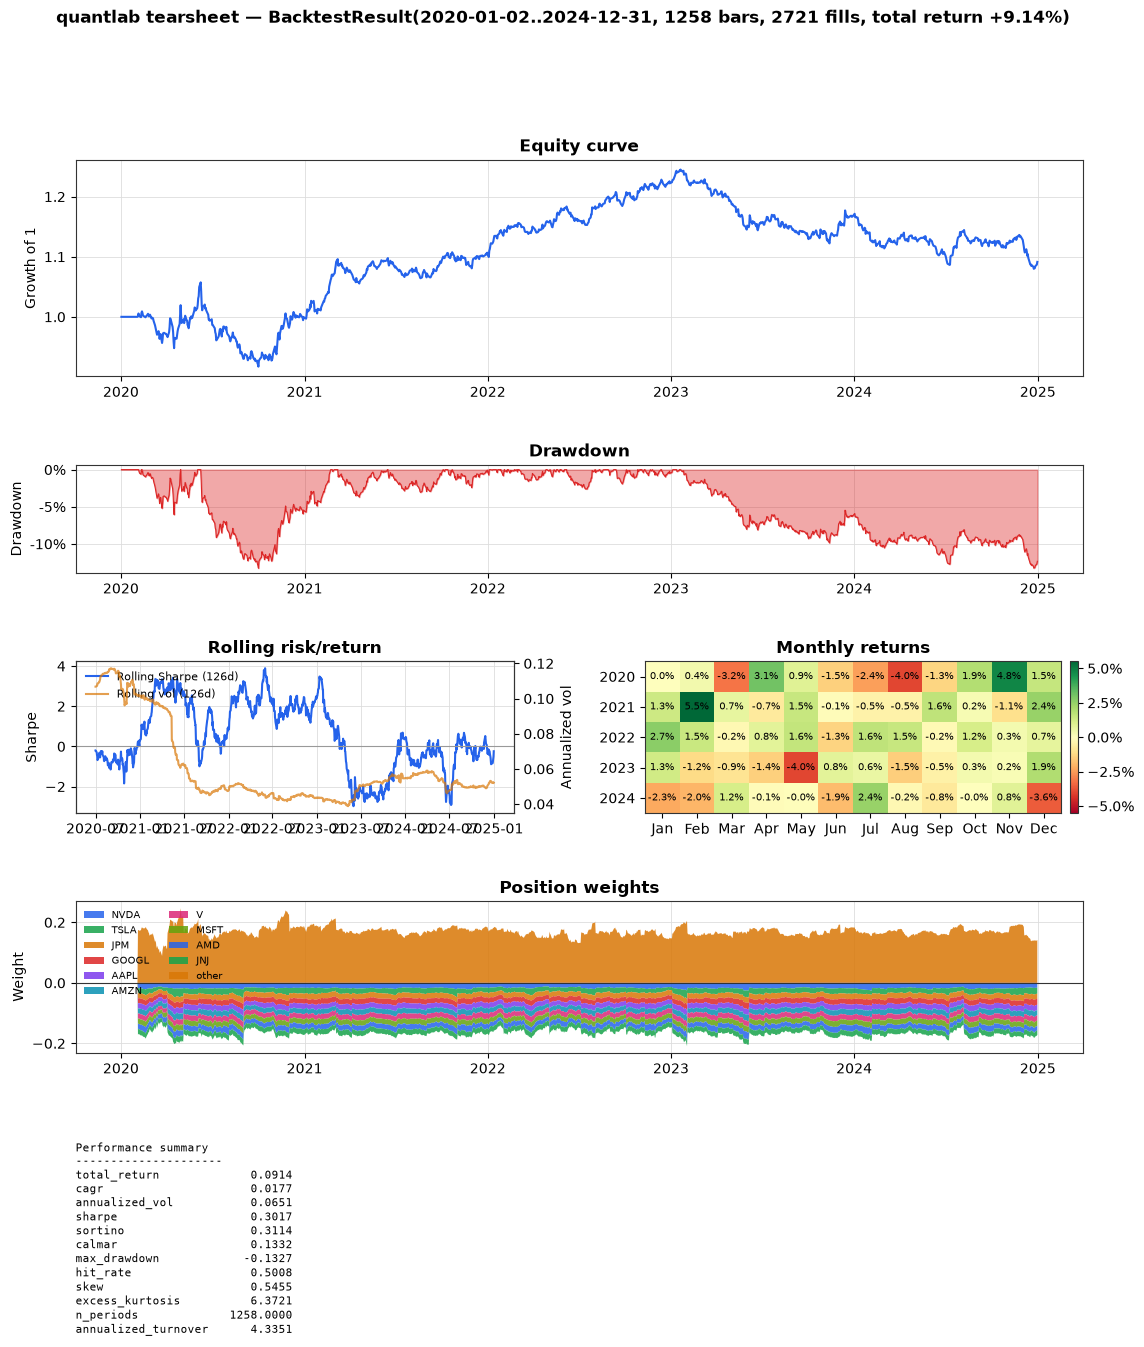

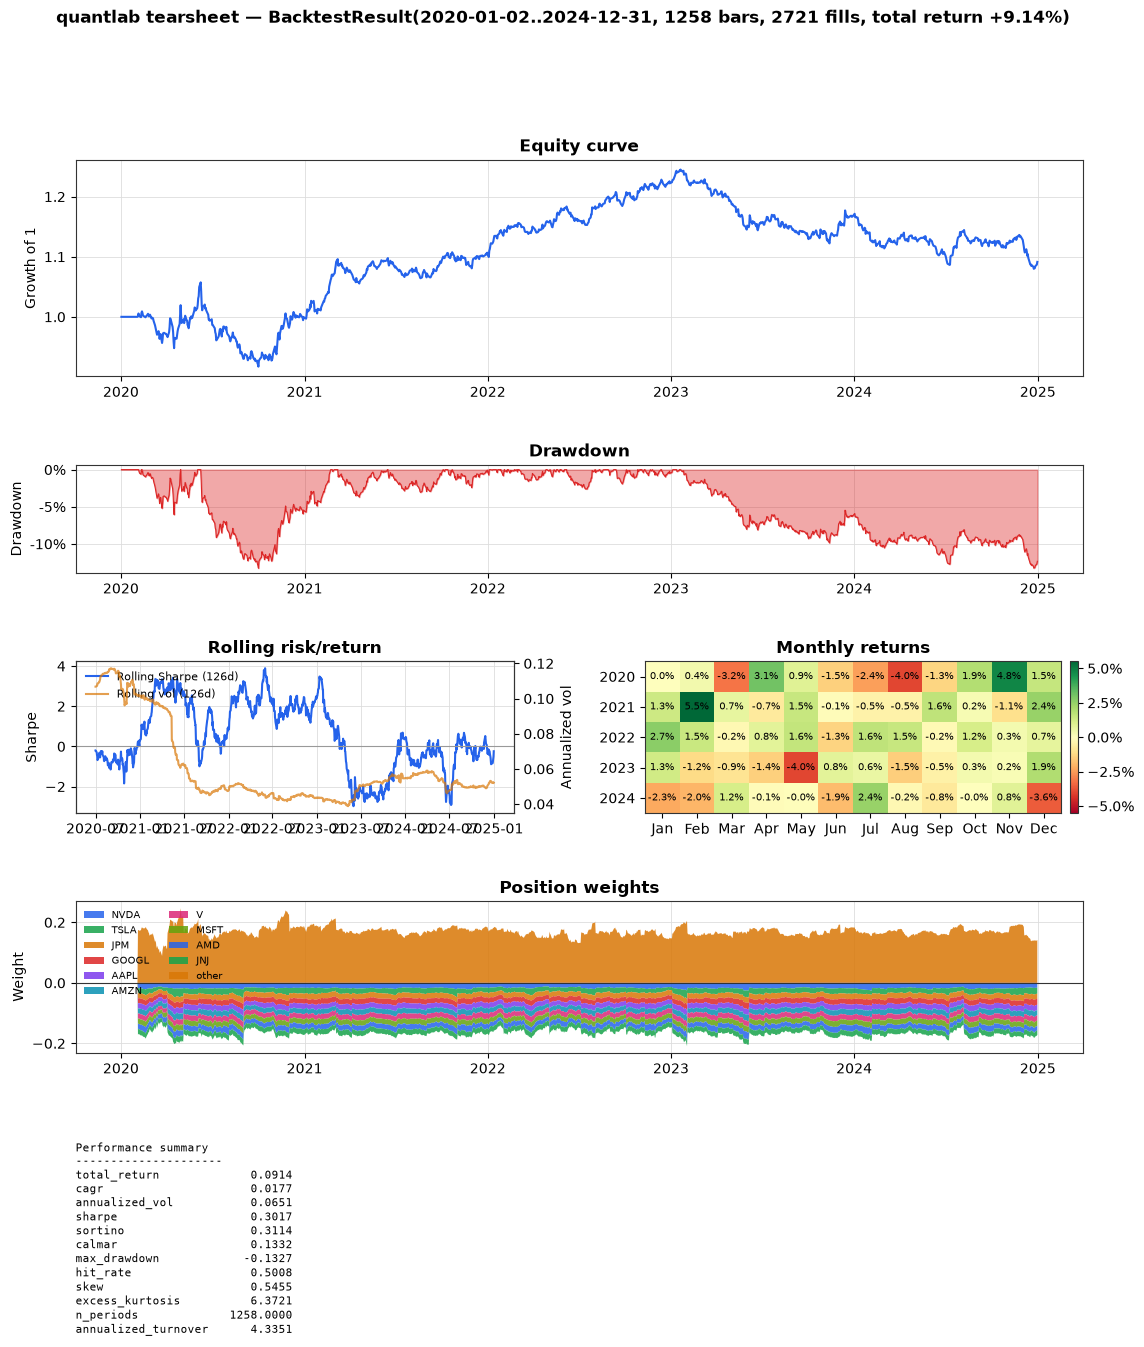

In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_tag = f"_{ML_MODEL}" if MODE == "ml" else ""
param_tag = f"{MODE}{model_tag}_{len(SELECTED_FACTORS)}f_{START_DATE}_{END_DATE}"
tearsheet_path = OUTPUT_DIR / f"{RUN_NAME}_{param_tag}_{timestamp}.png"

apply_style()
fig = tearsheet(main_result)
fig.savefig(tearsheet_path, dpi=150, bbox_inches="tight")
print(f"main result: {main_label}")
print(f"saved tearsheet to {tearsheet_path}")

fig


## Reading the results honestly

Before quoting anything from this notebook, re-check the caveats:

- **Survivorship**: this universe holds today's winners; the historical numbers are optimistic, full stop.
- **Fundamental coverage**: if Step 4 showed thin coverage, an ML run including fundamentals was fitted on the covered slice only — say so next to any result.
- **One walk-forward per configuration**: if you changed a knob after seeing a result and re-ran, the new result is no longer clean out-of-sample. The framework's `ExperimentTracker` exists to make that count auditable.
- **Red flags** (roadmap §3): IC above ~0.10 at a monthly horizon, a backtest that never draws down, or performance that collapses when the signal is lagged one day — investigate before reporting, every time.

**Next steps to try:** a different factor subset; `WINDOW_MODE="expanding"`; a stricter `PURGE_GAP = HORIZON + 21` with fundamentals; `TARGET_TRANSFORM="demeaned"`; and, later on the roadmap, gradient boosting and stacked ensembles as challengers to this Ridge baseline.
